# Ручное обогащение и проверка двух разметок

156 реальных отзывов и 51 фотография из публичных источников, собранных отдельно от UCI/Oxford. Исходные задания, происхождение и неизменённые экспорты — в `label_studio/`.

`initial` — первая разметка, `fixed` — предоставленные исправленные ответы. Если хотя бы один аннотатор пропустил объект, он остаётся пропущенным. Исправленное согласие не выдаётся за исходное независимое согласие.

Первые два EDA-ноутбука соответствуют ветке main. Этот ноутбук читает их CSV-разбиения; если они отсутствуют, сначала выполните 01 и 02. Метрики вынесены в небольшие скрипты по заданию; подготовка датасетов показана в ячейках.

In [1]:
from pathlib import Path
import sys, json, hashlib, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
from scipy.fft import dctn
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'label_studio/scripts'))
from annotation_io import load_pair, annotation, sentiment_label, image_filename, write_json
from sentiment_metrics import calculate as sentiment_metrics
from pets_metrics import calculate as pets_metrics

LS = ROOT / 'label_studio'
OUT = ROOT / 'data/processed/handmade'
ENRICHED = ROOT / 'data/processed/enriched'
OUT.mkdir(parents=True, exist_ok=True)
ENRICHED.mkdir(parents=True, exist_ok=True)
manifest = json.loads((LS / 'manifest.json').read_text())
assert (ROOT / 'data/processed/sentiment_splits.csv').exists(), 'Сначала выполните ноутбук 01'
assert (ROOT / 'data/processed/pets_splits.csv').exists(), 'Сначала выполните ноутбук 02'

## 1. Источники и объём

Объект текста — одно предложение/отзыв; объект сегментации — одна фотография, а не отдельный штрих кисти. Фотографии не объявляются собственными снимками: авторы и лицензии указаны в manifest.

In [2]:
text_sources = pd.DataFrame(manifest['sentiment_sources'])
photo_sources = pd.DataFrame(manifest['photos'])
assert text_sources.object_id.is_unique and photo_sources.object_id.is_unique
assert all((LS / file).exists() for file in photo_sources.file)
display(text_sources.source.value_counts().to_frame('reviews'))
display(pd.Series({'new_reviews': len(text_sources), 'new_photos': len(photo_sources),
                   'photo_authors': photo_sources.author.nunique()}).to_frame('count'))

,reviews
source,
Apple App Store (US),58
Yelp Review Full / Yelp,50
Amazon Reviews 2023 / McAuley Lab,48


,count
new_reviews,156
new_photos,51
photo_authors,48


**Вывод.** Собраны 156 отзывов (58 App Store, 48 Amazon, 50 Yelp) и 51 фотография. Для всех объектов сохранено происхождение; новые тексты и фотографии не являются синтетическими примерами из codebook.

## 2. Метрики initial и fixed

Cohen считается только для объектов с принятыми метками обоих. В IoU/Dice сравниваются исходные размеры масок, фон выводится отдельно; отсутствующий у обоих класс не получает искусственную единицу. Подробные формулы и CLI — в README аннотаций.

In [3]:
metric_rows, sentiment_results, pets_results = [], {}, {}
for stage in ['initial', 'fixed']:
    text_summary, text_audit = sentiment_metrics(stage)
    pet_summary, pet_classes, pet_audit = pets_metrics(stage, export_masks=(stage == 'fixed'))
    destination = LS / 'annotations/metrics' / stage
    write_json(text_summary, destination / 'sentiment_summary.json')
    write_json(pet_summary, destination / 'pets_summary.json')
    text_audit.to_csv(destination / 'sentiment_objects.csv', index=False)
    pet_classes.to_csv(destination / 'pets_per_image_class.csv', index=False)
    pet_audit.to_csv(destination / 'pets_objects.csv', index=False)
    sentiment_results[stage] = (text_summary, text_audit)
    pets_results[stage] = (pet_summary, pet_classes, pet_audit)
    metric_rows.append({'stage': stage, 'accepted_text_pairs': text_summary['paired_accepted'],
                       'skipped_texts': text_summary['excluded_any_skip'], 'Cohen_kappa': text_summary['cohen_kappa'],
                       'accepted_image_pairs': pet_summary['paired_accepted'],
                       'foreground_IoU': pet_summary['foreground_macro_iou'],
                       'foreground_Dice': pet_summary['foreground_macro_dice']})
display(pd.DataFrame(metric_rows))
display(pd.DataFrame(pets_results['fixed'][0]['per_class_mean']).T)

,stage,accepted_text_pairs,skipped_texts,Cohen_kappa,accepted_image_pairs,foreground_IoU,foreground_Dice
0,initial,142,14,0.956996,51,0.908013,0.951433
1,fixed,142,14,1.000000,51,0.909636,0.952385


,iou,dice
background,0.966421,0.982520
cat,0.923738,0.960241
dog,0.896076,0.944830


**Вывод.** На 142 принятых отзывах κ выросла с 0,957 до 1,000; 14 пропусков исключены из обеих бинарных оценок. Для fixed средний IoU животных ≈0,910, Dice ≈0,952. Это согласие двух разметок, а не качество обученной модели.

## 3. Итог текстовой разметки: skip остаётся skip

При совпадении принятых меток берём общую метку; любой skip исключает объект, возможное оставшееся расхождение получает review_required. Исходные JSON не редактируются.

In [4]:
first, second = load_pair('sentiment', 'fixed')
rows = []
for object_id in sorted(first):
    a, b = sentiment_label(first[object_id]), sentiment_label(second[object_id])
    status = 'skip' if a is None or b is None else 'accepted' if a == b else 'review_required'
    rows.append({'object_id': object_id, 'text': first[object_id]['data']['text'],
                 'label_1': a, 'label_2': b, 'label': a if status == 'accepted' else None,
                 'status': status, 'annotation_stage': 'fixed',
                 'codebook_version_export_1': first[object_id]['data'].get('codebook_version'),
                 'codebook_version_export_2': second[object_id]['data'].get('codebook_version')})
manual_text_all = pd.DataFrame(rows).merge(text_sources, on='object_id', validate='one_to_one')
manual_text_all['origin'] = 'handmade'
manual_text_all.to_csv(OUT / 'sentiment_all.csv', index=False)
manual_text = manual_text_all[manual_text_all.status.eq('accepted')].copy()
manual_text['label'] = manual_text.label.astype(int)
manual_text.to_csv(OUT / 'sentiment.csv', index=False)
display(manual_text_all.status.value_counts())
display(manual_text.label.value_counts().sort_index())
display(manual_text_all[manual_text_all.status.eq('skip')][['object_id', 'label_1', 'label_2', 'status']])
assert len(manual_text) >= 50

status
accepted    142
skip         14
Name: count, dtype: int64

label
0    61
1    81
Name: count, dtype: int64

,object_id,label_1,label_2,status
4,sent_005,0,NaN,skip
7,sent_008,1,NaN,skip
13,sent_015,0,NaN,skip
33,sent_035,1,NaN,skip
41,sent_043,0,NaN,skip
44,sent_046,0,NaN,skip
45,sent_047,0,NaN,skip
46,sent_049,1,NaN,skip
48,sent_051,0,NaN,skip
73,sent_076,0,NaN,skip


**Вывод.** Итоговая добавка — 142 отзыва (61 negative, 81 positive). Все 14 skip сохранены в аудите и не попадают в обучение. Никакие метки и объяснения за аннотаторов не придуманы.

## 4. Обогащённый текстовый датасет и проверка утечки

Сохраняем исходные validation/test. Новые вручную размеченные данные добавляем только в train. Проверяем дубликаты до объединения и пересечения после него.

In [5]:
def normalize_text(text):
    text = unicodedata.normalize('NFC', text).casefold()
    text = ''.join(' ' if unicodedata.category(char).startswith('P') else char for char in text)
    return ' '.join(text.split())

base_text = pd.read_csv(ROOT / 'data/processed/sentiment_splits.csv').rename(columns={'id': 'object_id'})
base_text['origin'] = 'uci'
base_text['normalized'] = base_text.text.map(normalize_text)
base_text['group_id'] = base_text.normalized.map(lambda text: 'uci_' + hashlib.sha256(text.encode()).hexdigest()[:16])
manual_text['normalized'] = manual_text.text.map(normalize_text)
assert manual_text.normalized.is_unique
assert not set(manual_text.normalized) & set(base_text.normalized)
manual_text['split'] = 'train'
columns = ['object_id', 'text', 'label', 'source', 'source_url', 'group_id', 'origin', 'split', 'normalized']
base_text['source_url'] = 'https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences'
enriched_text = pd.concat([base_text[columns], manual_text[columns]], ignore_index=True)
assert enriched_text.object_id.is_unique and enriched_text.normalized.is_unique
assert enriched_text.groupby('group_id').split.nunique().max() == 1
for split in ['validation', 'test']:
    assert set(enriched_text.loc[enriched_text.split.eq(split), 'object_id']) == set(base_text.loc[base_text.split.eq(split), 'object_id'])
enriched_text.to_csv(ENRICHED / 'sentiment.csv', index=False)
display(pd.crosstab(enriched_text.split, enriched_text.origin))
display(pd.crosstab(enriched_text.origin, enriched_text.label))

origin,handmade,uci
split,,
test,0,446
train,142,2080
validation,0,446


label,0,1
origin,,
handmade,61,81
uci,1486,1486


**Вывод.** 2972 уникальных исходных отзыва + 142 новых = 3114. В train — 2222, validation/test — по 446. Совпадений нормализованных текстов нет, исходные контрольные выборки сохранены. Новые данные не образуют отдельный тест нового домена.

## 5. Маски двух аннотаторов и область согласия

Скрипт уже сохранил маски обоих аннотаторов и производную маску agreement: если пиксели совпали, сохраняется класс; иначе 255. Это консервативная область согласия, а не экспертно выбранная новая граница. Повторные штрихи Cat/Cat объединяются; конфликт Cat/Dog внутри одной разметки вызывает ошибку.

In [6]:
first, second = load_pair('pets', 'fixed')
pet_summary, pet_classes, pet_audit = pets_results['fixed']
manual_pets = photo_sources.merge(pet_audit, on='object_id', validate='one_to_one')
manual_pets['image_path'] = 'label_studio/' + manual_pets.file
manual_pets['mask_path'] = manual_pets.object_id.map(lambda key: f'data/processed/handmade/masks/agreement/{key}.png')
manual_pets['origin'] = 'handmade'
manual_pets['annotation_stage'] = 'fixed'
manual_pets['mask_rule'] = 'equal_pixel_else_255'
manual_pets['codebook_version_export_1'] = manual_pets.object_id.map(lambda key: first[key]['data'].get('codebook_version'))
manual_pets['codebook_version_export_2'] = manual_pets.object_id.map(lambda key: second[key]['data'].get('codebook_version'))
manual_pets['ignore_fraction'] = manual_pets.uncertain_pixels / manual_pets.pixels
print(f"Неопределённых пикселей (сумма по исходным разрешениям): {pet_summary['uncertain_fraction_pooled']:.2%}")
display(manual_pets[['object_id', 'status', 'ignore_fraction']].head())

Неопределённых пикселей (сумма по исходным разрешениям): 2.06%


,object_id,status,ignore_fraction
0,pet_001,accepted,0.050669
1,pet_002,accepted,0.018875
2,pet_003,accepted,0.051212
3,pet_004,accepted,0.018481
4,pet_005,accepted,0.039799


**Вывод.** Для всех 51 фотографий получены корректно декодированные пары. Около 2,06% пикселей расходятся и не участвуют в loss/метриках целевой маски. У pets-1-fixed версия codebook в JSON отсутствует; это не исправляется задним числом, пропуск метаданных сохранён.

## 6. Где аннотаторы расходятся сильнее

,iou,dice
object_id,,
pet_089,0.840713,0.913465
pet_078,0.841510,0.913935
pet_088,0.848651,0.918130


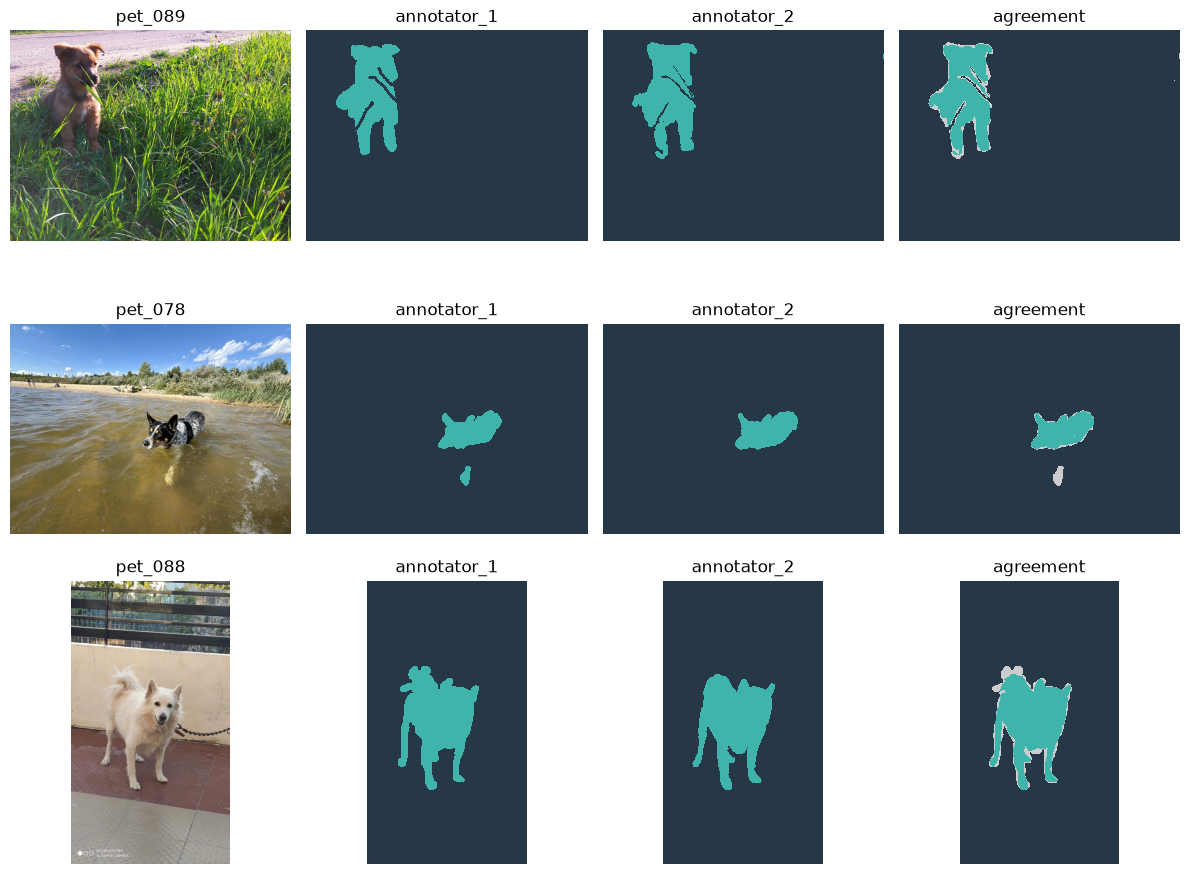

In [7]:
foreground = pet_classes[pet_classes.class_id.isin([1, 2])]
worst_ids = list(foreground.groupby('object_id').iou.mean().nsmallest(3).index)
display(foreground.groupby('object_id')[['iou', 'dice']].mean().loc[worst_ids])
colors = ListedColormap(['#263747', '#f59e42', '#3eb4aa'])
colors.set_bad('#cccccc')
fig, axes = plt.subplots(len(worst_ids), 4, figsize=(12, 3 * len(worst_ids)), squeeze=False)
for row_axes, key in zip(axes, worst_ids):
    source = manual_pets[manual_pets.object_id.eq(key)].iloc[0]
    with Image.open(ROOT / source.image_path) as image:
        row_axes[0].imshow(image.convert('RGB'))
    row_axes[0].set_title(key)
    for ax, name in zip(row_axes[1:], ['annotator_1', 'annotator_2', 'agreement']):
        with Image.open(OUT / f'masks/{name}/{key}.png') as image:
            mask = np.asarray(image)
        ax.imshow(np.ma.masked_equal(mask, 255), cmap=colors, vmin=0, vmax=2, interpolation='nearest')
        ax.set_title(name)
    for ax in row_axes:
        ax.axis('off')
plt.tight_layout()
plt.show()

**Вывод.** Числовые метрики дополнены просмотром границ. Даже после fixed маски не обязаны совпадать полностью; усреднение индексов классов или выбор одного аннотатора без основания не используется.

## 7. Проверка новых фотографий: файлы, дубликаты, близость к Oxford

Считаем SHA-256 файла и RGB, а также тот же pHash, что в EDA. При точном или близком (Hamming ≤6) совпадении с исходными изображениями оставляем строку в аудите, но не включаем её в добавку без проверки.

In [8]:
base_pets = pd.read_csv(ROOT / 'data/processed/pets_splits.csv', dtype={'phash': str})
hex_hashes = base_pets.phash.str.contains('[a-fA-F]', regex=True).any()
base_hashes = np.array([int(value, 16 if hex_hashes else 10) for value in base_pets.phash], dtype=np.uint64)
popcount = np.array([value.bit_count() for value in range(256)], dtype=np.uint8)
file_checks, near_rows = [], []
for row in manual_pets.itertuples():
    path = ROOT / row.image_path
    with Image.open(path) as image:
        image.load()
        rgb = np.asarray(image.convert('RGB'))
    pixel_hash = hashlib.sha256(str(rgb.shape).encode() + rgb.tobytes()).hexdigest()
    file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    thumbnail = Image.fromarray(rgb).convert('L').resize((32, 32), Image.Resampling.LANCZOS)
    coefficients = dctn(np.asarray(thumbnail, dtype=float), norm='ortho')[:8, :8].ravel()
    bits = coefficients > np.median(coefficients[1:])
    bits[0] = False
    phash = int.from_bytes(np.packbits(bits).tobytes(), 'big')
    difference = np.bitwise_xor(np.uint64(phash), base_hashes)
    distances = popcount[difference.view(np.uint8).reshape(-1, 8)].sum(axis=1)
    for index in np.flatnonzero(distances <= 6):
        near_rows.append({'object_id': row.object_id, 'oxford_id': base_pets.iloc[index].id,
                          'oxford_split': base_pets.iloc[index].split, 'phash_distance': int(distances[index])})
    exact = file_hash in set(base_pets.sha256) or pixel_hash in set(base_pets.pixel_sha256)
    file_checks.append({'object_id': row.object_id, 'sha256': file_hash, 'pixel_sha256': pixel_hash,
                        'exact_original_overlap': exact, 'near_original_overlap': bool((distances <= 6).any())})
checks = pd.DataFrame(file_checks)
assert checks.sha256.is_unique and checks.pixel_sha256.is_unique
manual_pets = manual_pets.merge(checks, on='object_id', validate='one_to_one')
near_original = pd.DataFrame(near_rows, columns=['object_id', 'oxford_id', 'oxford_split', 'phash_distance'])
near_original.to_csv(OUT / 'pets_original_overlap_candidates.csv', index=False)
display(checks[['exact_original_overlap', 'near_original_overlap']].value_counts().to_frame('photos'))
display(near_original)

,,photos
exact_original_overlap,near_original_overlap,
False,False,51


,object_id,oxford_id,oxford_split,phash_distance


**Вывод.** Проверка не ограничивается разными именами файлов: проверяются точное содержимое и визуальная близость к исходным данным. pHash не устанавливает идентичность животных; группировка новых фото использует group_id из источников.

## 8. Итоговый датасет сегментации

Новые фотографии добавляются только в train. Маски Oxford без foreground исключаются из train/validation, но официальный test не изменяется. Причины исключений сохраняются в манифесте; исходные файлы и разбиения EDA не перезаписываются.

In [9]:
manual_pets['empty_foreground'] = False
species_names = []
for row in manual_pets.itertuples():
    if row.status == 'skip':
        species_names.append('unreviewed')
        continue
    with Image.open(ROOT / row.mask_path) as image:
        mask = np.asarray(image)
    assert mask.shape == (int(row.height), int(row.width))
    assert set(np.unique(mask)) <= {0, 1, 2, 255}
    present = set(np.unique(mask)) & {1, 2}
    species_names.append('cat' if present == {1} else 'dog' if present == {2} else 'mixed')
    manual_pets.loc[manual_pets.object_id.eq(row.object_id), 'empty_foreground'] = not present
manual_pets['species_name'] = species_names
manual_pets['split'] = 'train'
manual_pets.loc[manual_pets.status.eq('skip'), 'split'] = 'excluded_skip'
manual_pets.loc[manual_pets.exact_original_overlap | manual_pets.near_original_overlap, 'split'] = 'excluded_original_overlap'
manual_pets.loc[manual_pets.empty_foreground, 'split'] = 'excluded_empty_mask'
manual_pets.to_csv(OUT / 'pets.csv', index=False)

original = base_pets.rename(columns={'id': 'object_id'}).copy()
original['origin'] = 'oxford'
original['group_id'] = 'oxford_' + original.duplicate_group.astype(str)
original['source_url'] = 'https://www.robots.ox.ac.uk/~vgg/data/pets/'
original['base_split'] = original.split
bad_training_mask = original.empty_foreground & original.split.isin(['train', 'validation'])
original.loc[bad_training_mask, 'split'] = 'excluded_empty_mask'
columns = ['object_id', 'image_path', 'mask_path', 'species_name', 'group_id', 'origin', 'split', 'empty_foreground', 'source_url']
enriched_pets = pd.concat([original[columns], manual_pets[columns]], ignore_index=True)
assert enriched_pets.object_id.is_unique
selected = enriched_pets[enriched_pets.split.isin(['train', 'validation', 'test'])]
assert selected.groupby('group_id').split.nunique().max() == 1
assert set(enriched_pets.loc[enriched_pets.split.eq('test'), 'object_id']) == set(base_pets.loc[base_pets.split.eq('test'), 'id'])
for row in selected.itertuples():
    assert (ROOT / row.image_path).exists() and (ROOT / row.mask_path).exists()
enriched_pets.to_csv(ENRICHED / 'pets.csv', index=False)
display(pd.crosstab(enriched_pets.split, enriched_pets.origin))
display(manual_pets.groupby(['split', 'species_name']).size().to_frame('photos'))

origin,handmade,oxford
split,,
excluded_empty_mask,0,7
excluded_test_overlap,0,24
test,0,3669
train,51,2920
validation,0,729


photos
split species_name        
train cat               25
      dog               26

**Вывод.** Итоговые наборы отделены от исходных EDA-разбиений. Сохраняются provenance, группы, skip и причины исключения; контрольный test Oxford остаётся исходным. Для сегментации нужна функция потерь с ignore_index=255. Файлы с excluded_* не подаются в обучение.

## 9. Что готово и что означает результат

- Более 50 одинаковых объектов обработано двумя аннотаторами для каждой задачи: 156 отзывов и 51 фотография; после skip для текста остаётся 142 пары.
- Codebook — в `docs/`, исходные и исправленные экспорты сохранены отдельно.
- Метрики initial/fixed и аудит каждого объекта — в `label_studio/annotations/metrics/`.
- Дополнительные данные и PNG-маски — `data/processed/handmade/`; объединённые манифесты — `data/processed/enriched/`.
- Эти метрики измеряют согласие аннотаторов. Модель ещё не обучалась. Согласие по пикселям не гарантирует отсутствие общей ошибки обоих людей.
- Производная маска agreement не заменяет экспертное разрешение всех спорных границ: разногласия исключены через 255.
- Источники новые, но представительность ограничена отбором приложений/отзывов и фотографий; перенос на новые условия требует отдельной проверки.